In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

df = pd.read_csv('KO_weekly_return_detailed.csv')

weekly = df.groupby(['Year', 'Week_Number']).last().reset_index()[['Year', 'Week_Number', 'Close']]
weekly = weekly.sort_values(['Year', 'Week_Number']).reset_index(drop=True)

train_weekly = weekly[weekly['Year'].isin([2021, 2022, 2023])].reset_index(drop=True)
test_weekly = weekly[weekly['Year'].isin([2024, 2025])].reset_index(drop=True)

train_prices = train_weekly['Close'].values
test_prices = test_weekly['Close'].values

print(train_weekly.shape)

def get_accuracy(prices, W, d):
    correct = 0
    total = 0
    for i in range(W, len(prices)):
        x = np.arange(W)
        y = prices[i-W:i]
        coeffs = np.polyfit(x, y, d)
        predicted = np.poly1d(coeffs)(W)
        actual_label = 'YES' if prices[i] > prices[i-1] else 'NO'
        if predicted > prices[i-1]:
            pred_label = 'YES'
        elif predicted < prices[i-1]:
            pred_label = 'NO'
        else:
            pred_label = actual_label
        if pred_label == actual_label:
            correct += 1
        total += 1
    return round(correct / total * 100, 2)

(156, 3)


## Q1 : For W=5..12 and d=1,2,3 compute accuracy on training years and plot


d=1, W=5, accuracy=52.98%
d=1, W=6, accuracy=53.33%
d=1, W=7, accuracy=48.99%
d=1, W=8, accuracy=47.3%
d=1, W=9, accuracy=44.9%
d=1, W=10, accuracy=45.21%
d=1, W=11, accuracy=44.83%
d=1, W=12, accuracy=44.44%
d=2, W=5, accuracy=50.33%
d=2, W=6, accuracy=51.33%
d=2, W=7, accuracy=51.68%
d=2, W=8, accuracy=50.68%
d=2, W=9, accuracy=48.98%
d=2, W=10, accuracy=57.53%
d=2, W=11, accuracy=55.86%
d=2, W=12, accuracy=54.17%
d=3, W=5, accuracy=50.33%
d=3, W=6, accuracy=50.0%
d=3, W=7, accuracy=48.32%
d=3, W=8, accuracy=52.03%
d=3, W=9, accuracy=50.34%
d=3, W=10, accuracy=49.32%
d=3, W=11, accuracy=49.66%
d=3, W=12, accuracy=50.69%


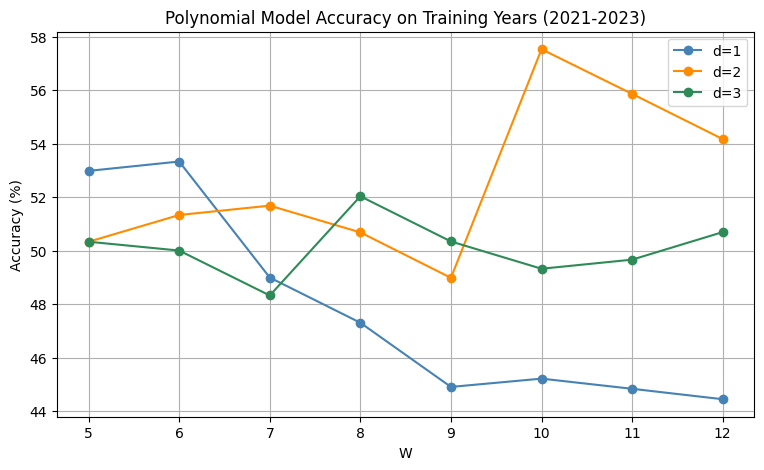

In [2]:
W_values = list(range(5, 13))
degrees = [1, 2, 3]
colors = ['steelblue', 'darkorange', 'seagreen']

all_accs = {}
for d in degrees:
    accs = []
    for W in W_values:
        acc = get_accuracy(train_prices, W, d)
        accs.append(acc)
        print(f'd={d}, W={W}, accuracy={acc}%')
    all_accs[d] = accs

plt.figure(figsize=(9, 5))
for d, color in zip(degrees, colors):
    plt.plot(W_values, all_accs[d], marker='o', color=color, label=f'd={d}')
plt.xlabel('W')
plt.ylabel('Accuracy (%)')
plt.title('Polynomial Model Accuracy on Training Years (2021-2023)')
plt.xticks(W_values)
plt.legend()
plt.grid(True)
plt.savefig('poly_accuracy_training.png')
plt.show()

## Q2 : For each d use best W to predict labels for years 4 and 5 — what is accuracy?

In [3]:
best_W = {}
for d in degrees:
    best_W[d] = W_values[np.argmax(all_accs[d])]
    print(f'd={d}, best W={best_W[d]}, training accuracy={max(all_accs[d])}%')

all_prices = np.concatenate([train_prices, test_prices])
test_start = len(train_prices)

test_results = {}
for d in degrees:
    W = best_W[d]
    preds = []
    actuals = []
    for i in range(test_start, len(all_prices)):
        x = np.arange(W)
        y = all_prices[i-W:i]
        coeffs = np.polyfit(x, y, d)
        predicted = np.poly1d(coeffs)(W)
        actual_label = 'YES' if all_prices[i] > all_prices[i-1] else 'NO'
        if predicted > all_prices[i-1]:
            pred_label = 'YES'
        elif predicted < all_prices[i-1]:
            pred_label = 'NO'
        else:
            pred_label = actual_label
        preds.append(pred_label)
        actuals.append(actual_label)

    preds = np.array(preds)
    actuals = np.array(actuals)
    acc = round(np.mean(preds == actuals) * 100, 2)
    test_results[d] = (acc, preds, actuals)
    print(f'd={d}, W={W}, test accuracy={acc}%')

d=1, best W=6, training accuracy=53.33%
d=2, best W=10, training accuracy=57.53%
d=3, best W=8, training accuracy=52.03%
d=1, W=6, test accuracy=46.23%
d=2, W=10, test accuracy=46.23%
d=3, W=8, test accuracy=57.55%


## Q3 : Confusion matrices for each d for testing years


In [6]:
# combined confusion matrix
for d in degrees:
    acc, preds, actuals = test_results[d]
    cm = confusion_matrix(actuals, preds, labels=['YES', 'NO'])
    print(f'\nd={d} (W={best_W[d]}) - Combined:')
    print(f'  Predicted YES  Predicted NO')
    print(f'Actual YES  {cm[0][0]}           {cm[0][1]}')
    print(f'Actual NO   {cm[1][0]}           {cm[1][1]}')

# year 4 and year 5 separately
for d in degrees:
    W = best_W[d]
    print(f'\nd={d} (W={W}):')
    for yr in [2024, 2025]:
        yr_weekly = test_weekly[test_weekly['Year'] == yr].reset_index(drop=True)
        yr_daily = df[df['Year'] == yr].reset_index(drop=True)
        yr_preds = []
        yr_actuals = []
        for i in range(len(yr_weekly)):
            global_idx = test_weekly[test_weekly['Year'] == yr].index[i]
            if global_idx < W:
                continue
            y = all_prices[global_idx - W: global_idx]
            x = np.arange(W)
            coeffs = np.polyfit(x, y, d)
            predicted = np.poly1d(coeffs)(W)
            actual_label = 'YES' if all_prices[global_idx] > all_prices[global_idx - 1] else 'NO'
            if predicted > all_prices[global_idx - 1]:
                pred_label = 'YES'
            elif predicted < all_prices[global_idx - 1]:
                pred_label = 'NO'
            else:
                pred_label = actual_label
            yr_preds.append(pred_label)
            yr_actuals.append(actual_label)
        cm_yr = confusion_matrix(yr_actuals, yr_preds, labels=['YES', 'NO'])
        print(f'  Year {yr}:')
        print(f'    Predicted YES  Predicted NO')
        print(f'  Actual YES  {cm_yr[0][0]}           {cm_yr[0][1]}')
        print(f'  Actual NO   {cm_yr[1][0]}           {cm_yr[1][1]}')


d=1 (W=6) - Combined:
  Predicted YES  Predicted NO
Actual YES  28           27
Actual NO   30           21

d=2 (W=10) - Combined:
  Predicted YES  Predicted NO
Actual YES  28           27
Actual NO   30           21

d=3 (W=8) - Combined:
  Predicted YES  Predicted NO
Actual YES  32           23
Actual NO   22           29

d=1 (W=6):
  Year 2024:
    Predicted YES  Predicted NO
  Actual YES  14           13
  Actual NO   14           6
  Year 2025:
    Predicted YES  Predicted NO
  Actual YES  17           10
  Actual NO   13           13

d=2 (W=10):
  Year 2024:
    Predicted YES  Predicted NO
  Actual YES  16           10
  Actual NO   8           9
  Year 2025:
    Predicted YES  Predicted NO
  Actual YES  14           13
  Actual NO   11           15

d=3 (W=8):
  Year 2024:
    Predicted YES  Predicted NO
  Actual YES  17           10
  Actual NO   7           11
  Year 2025:
    Predicted YES  Predicted NO
  Actual YES  11           16
  Actual NO   13           13


## Q4 : Trading strategy for each d vs buy-and-hold


In [5]:
daily_test = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)
final_balances = {}

for d in degrees:
    acc, preds, actuals = test_results[d]
    test_weekly_trimmed = test_weekly.iloc[:len(preds)].copy().reset_index(drop=True)
    test_weekly_trimmed['prediction'] = preds

    balance = 100
    position = None

    for week_idx in range(len(test_weekly_trimmed)):
        current_week = test_weekly_trimmed.iloc[week_idx]
        year = current_week['Year']
        week_num = current_week['Week_Number']
        week_data = daily_test[(daily_test['Year'] == year) & (daily_test['Week_Number'] == week_num)]

        if len(week_data) == 0:
            continue

        if position == 'invested':
            for idx, row in week_data.iterrows():
                if pd.notna(row['Return']):
                    balance = balance * (1 + row['Return'] / 100)

        if week_idx < len(test_weekly_trimmed) - 1:
            next_prediction = test_weekly_trimmed.iloc[week_idx + 1]['prediction']
            position = 'invested' if next_prediction == 'YES' else None

    final_balances[d] = balance
    print(f'd={d} Strategy Final Balance: ${balance:.2f}')

bh_balance = 100
for idx, row in daily_test.iterrows():
    if pd.notna(row['Return']):
        bh_balance = bh_balance * (1 + row['Return'] / 100)

print(f'Buy and Hold Final Balance: ${bh_balance:.2f}')
all_strats = {f'd={d}': final_balances[d] for d in degrees}
all_strats['Buy and Hold'] = bh_balance
winner = max(all_strats, key=all_strats.get)
print(f'{winner} results in a larger amount at the end of the testing period')

d=1 Strategy Final Balance: $109.09
d=2 Strategy Final Balance: $121.56
d=3 Strategy Final Balance: $123.44
Buy and Hold Final Balance: $126.14
Buy and Hold results in a larger amount at the end of the testing period
